# A549 Perturb-seq | CRISPR Perturbation Response Profiling with Seurat

**Reproducible exploratory single-cell analysis · R / Seurat v5 · two 10x capture channels**

This notebook investigates transcriptional responses to pooled gene perturbations in the A549 lung cancer cell line. It combines channel-aware quality control, single-cell embedding, non-targeting-control (NTC) comparisons, on-target response assessment, pathway interpretation, and perturbation-signature similarity.

> **Interpretation:** A549 cells are a relatively homogeneous cell line. An overlapping or continuous UMAP is not evidence that the screen failed; perturbation-specific expression signatures and adequate controls are more informative than sharply separated clusters. 

## Workflow

1. Configure file paths and check required packages.
2. Import two AnnData files, verify that expression contains **raw counts**, and merge with unique channel-prefixed cell IDs.
3. Assess QC, normalize using SCTransform, and explore PCA/UMAP without forcing batch correction.
4. Inspect perturbation coverage and channel balance.
5. Run exploratory perturbation-versus-NTC differential expression; examine volcano plots and on-target expression.
6. Compare response signatures, run GO enrichment, evaluate channel concordance, and export summary tables.


In [1]:
suppressPackageStartupMessages({
  library(Seurat)
  library(anndata)
  library(Matrix)
  library(dplyr)
  library(tidyr)
  library(tibble)
  library(ggplot2)
  library(glue)
})
set.seed(42)

# Set to the folder containing the two .h5ad files.
data_dir <- '/media/josh/samsung/data/perturbseq/Fellinger_A549'
file_ch1 <- file.path(data_dir, "GSE337804_A549_ch_1.RDS.h5ad")
file_ch2 <- file.path(data_dir, "GSE337804_A549_ch_2.RDS.h5ad")
results_dir <- "results" # Gitignored by default

# Optional: choose a specific metadata column / NTC label after inspecting metadata.
perturb_col_override <- NULL   # e.g. "perturbation" or "sgrna_symbol"
ntc_labels_override <- NULL   # e.g. c("non-targeting", "non_targeting")
min_cells_per_group <- 25
max_targets_to_test <- 12 

stopifnot(file.exists(file_ch1), file.exists(file_ch2))
dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
cat("Input files found in:", normalizePath(data_dir), "\n")

Input files found in: /media/josh/samsung/data/perturbseq/Fellinger_A549 


## 1. Import and merge the two channels

10x cell barcodes can recur across independent capture channels. Prefixing with `Ch1_` and `Ch2_` prevents collisions. These two channels are **not automatically independent biological replicates**. 

In [2]:
# Expect observations (cells) × variables (genes) in AnnData.
# Read `.X` into R using anndata's Python-backed interface.
ad1 <- anndata::read_h5ad(file_ch1)
ad2 <- anndata::read_h5ad(file_ch2)

convert_h5ad_to_seurat <- function(ad_obj, channel_name) {
  x <- ad_obj$X
  if (!inherits(x, "Matrix")) x <- as.matrix(x)
  if (nrow(x) != nrow(ad_obj$obs) || ncol(x) != nrow(ad_obj$var)) {
    stop("AnnData matrix dimensions do not match obs/var. Inspect file structure.")
  }
  x <- Matrix::t(x)
  colnames(x) <- rownames(ad_obj$obs)
  rownames(x) <- rownames(ad_obj$var)
  if (anyNA(x) || any(x < 0)) stop("Negative or missing expression values found.")
  probe <- if (inherits(x, "sparseMatrix")) x@x else as.numeric(x)
  if (length(probe) && any(abs(probe - round(probe)) > 1e-6)) {
    stop("AnnData .X contains non-integer values, likely normalized data. Locate raw UMI counts in .layers or .raw before proceeding.")
  }
  if (anyDuplicated(rownames(x)) || anyDuplicated(colnames(x))) {
    stop("Duplicate gene/cell IDs within one channel; resolve before import.")
  }
  seu <- CreateSeuratObject(counts = x, meta.data = as.data.frame(ad_obj$obs), project = channel_name)
  seu$channel <- channel_name
  seu
}

seu1 <- convert_h5ad_to_seurat(ad1, "Ch1")
seu2 <- convert_h5ad_to_seurat(ad2, "Ch2")

perturb_obj <- merge(seu1, y = seu2, add.cell.ids = c("Ch1", "Ch2"), project = "A549_PerturbSeq")
stopifnot(anyDuplicated(colnames(perturb_obj)) == 0L)
stopifnot(ncol(perturb_obj) == ncol(seu1) + ncol(seu2))
print(table(perturb_obj$channel))
print(perturb_obj)

Warning message:
“Data is of class dgRMatrix. Coercing to dgCMatrix.”
Warning message:
“Data is of class dgRMatrix. Coercing to dgCMatrix.”



  Ch1   Ch2 
25702 27809 
An object of class Seurat 
19039 features across 53511 samples within 1 assay 
Active assay: RNA (19039 features, 0 variable features)
 2 layers present: counts.Ch1, counts.Ch2


## 2. QC and normalized expression

These are **diagnostic plots**, not automatic exclusion criteria. Review the distribution of sequencing depth, detected genes, and mitochondrial percentage by channel before setting any filters. In Seurat v5, merging may leave separate RNA count layers; `JoinLayers()` combines them for a single joint normalization. This workflow assumes both files share compatible count conventions.

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


QC/SCTransform complete; cells retained: 53511 


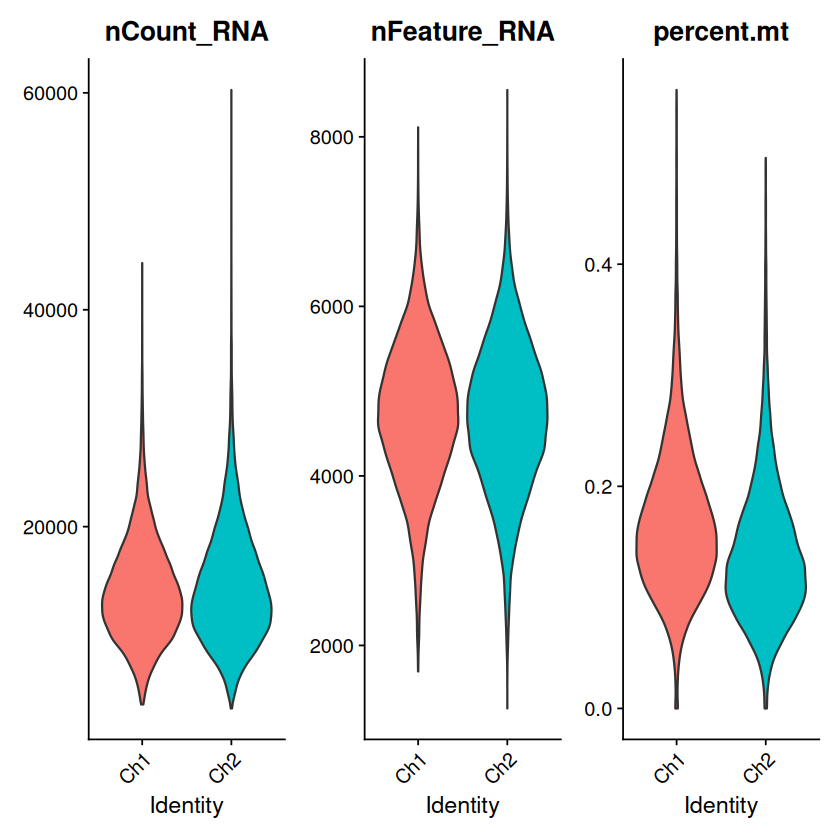

In [3]:
DefaultAssay(perturb_obj) <- "RNA"
if (inherits(perturb_obj[["RNA"]], "Assay5")) {
  perturb_obj <- JoinLayers(perturb_obj, assay = "RNA")
}
mt_genes <- grep("^MT-", rownames(perturb_obj), value = TRUE)
if (length(mt_genes)) {
  perturb_obj[["percent.mt"]] <- PercentageFeatureSet(perturb_obj, features = mt_genes)
} else {
  message("No MT- gene symbols found. Mitochondrial QC not available with current feature naming.")
}
qc_features <- intersect(c("nCount_RNA", "nFeature_RNA", "percent.mt"), colnames(perturb_obj@meta.data))
print(VlnPlot(perturb_obj, features = qc_features, group.by = "channel", pt.size = 0, ncol = length(qc_features)))
# Regress percent.mt only when meaningful mitochondrial percentage is available.
regress_vars <- if ("percent.mt" %in% qc_features) "percent.mt" else NULL
perturb_obj <- SCTransform(perturb_obj, vars.to.regress = regress_vars, verbose = FALSE)
cat("QC/SCTransform complete; cells retained:", ncol(perturb_obj), "\n")

## 3. PCA, UMAP, and clustering

Embeddings visualize global transcriptional structure; A549 cells may remain largely continuous despite reproducible perturbation-associated signatures. 

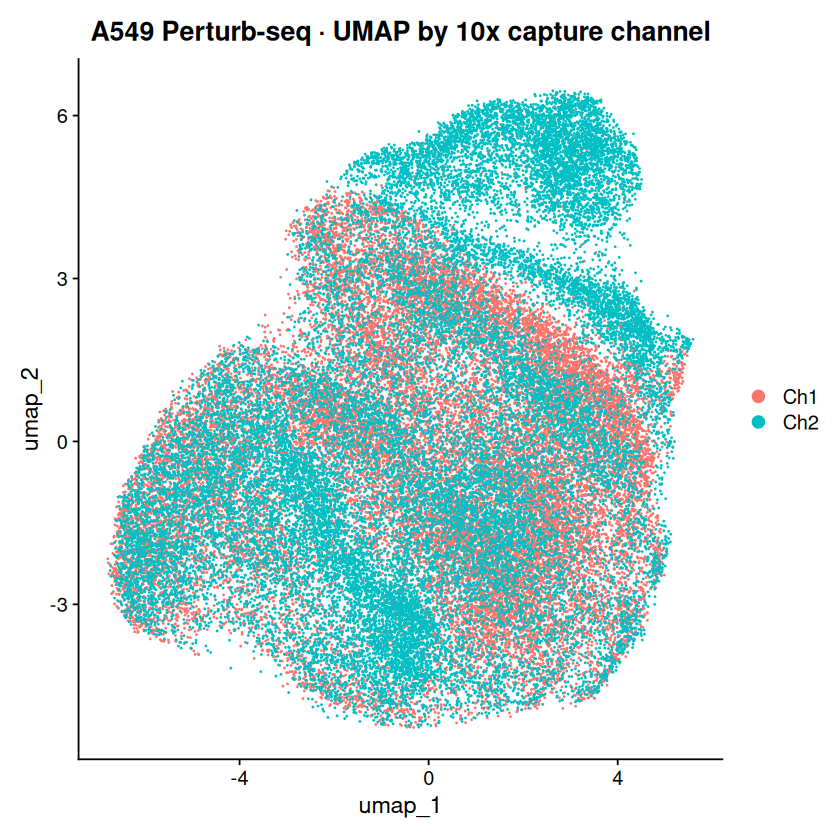

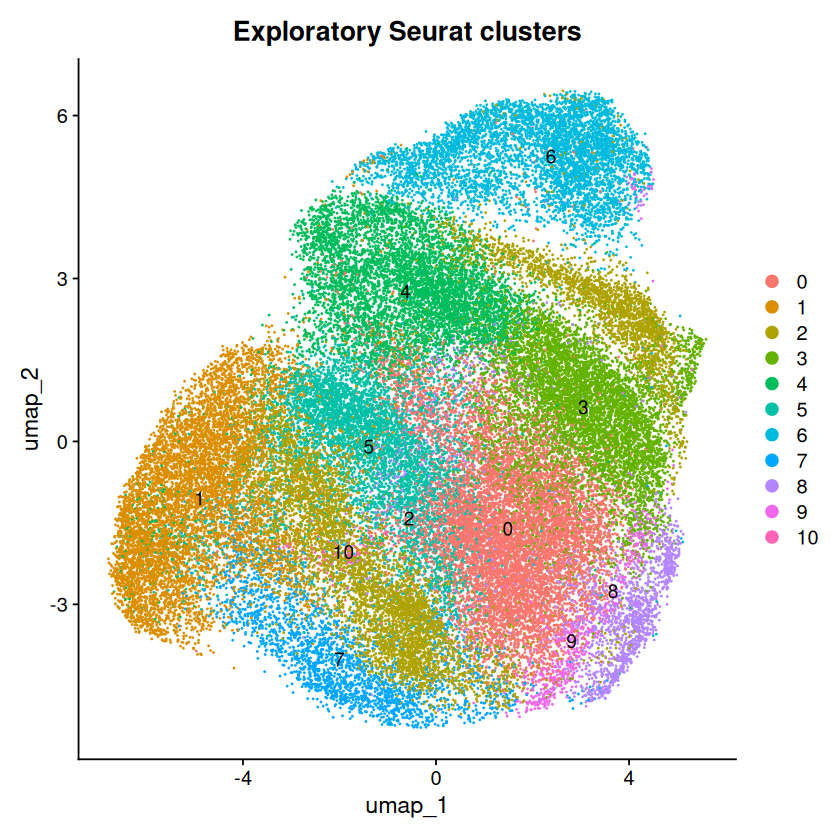

In [4]:
DefaultAssay(perturb_obj) <- "SCT"
perturb_obj <- RunPCA(perturb_obj, npcs = 30, verbose = FALSE)
perturb_obj <- FindNeighbors(perturb_obj, dims = 1:20, verbose = FALSE)
perturb_obj <- FindClusters(perturb_obj, resolution = 0.5, verbose = FALSE)
perturb_obj <- RunUMAP(perturb_obj, dims = 1:20, seed.use = 42, verbose = FALSE)
print(DimPlot(perturb_obj, reduction = "umap", group.by = "channel") +
        ggtitle("A549 Perturb-seq · UMAP by 10x capture channel"))
print(DimPlot(perturb_obj, reduction = "umap", group.by = "seurat_clusters", label = TRUE) +
        ggtitle("Exploratory Seurat clusters"))

In [5]:
head(perturb_obj@meta.data, 3)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,sgrna_id,sgrna_symbol,cl,channel,cl_channel,nCount_SCT,nFeature_SCT,SCT_snn_res.0.5,seurat_clusters
,<chr>,<dbl>,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<fct>,<fct>
Ch1_AAACCTGAGAATGTTG,8cl,14108,5004,0.2622625,non-targeting_20,non-targeting,A549,Ch1,A549_ch_1,13968,4961,7,7
Ch1_AAACCTGAGAATTCCC,8cl,8010,3589,0.3995006,LCP2_2,LCP2,A549,Ch1,A549_ch_1,12502,3709,1,1
Ch1_AAACCTGAGACATAAC,8cl,20350,5786,0.1621622,BCOR_3,BCOR,A549,Ch1,A549_ch_1,14487,5625,4,4


## 4. Metadata harmonization and non-targeting controls

The source exports may use `perturbation` or `sgrna_symbol` and different NTC spellings. 

In [6]:
md0 <- perturb_obj@meta.data
candidate_cols <- c("perturbation", "sgrna_symbol", "guide_target", "target_gene")
available_cols <- intersect(candidate_cols, colnames(md0))
if (!length(available_cols)) stop("No recognized perturbation column. Inspect colnames(perturb_obj@meta.data).")
control_pattern <- "^(non[-_ ]?targeting|non[-_ ]?target|ntc|negative[-_ ]?control)$"
if (!is.null(perturb_col_override)) {
  stopifnot(perturb_col_override %in% available_cols)
  perturb_col <- perturb_col_override
} else {
  n_ntc <- vapply(available_cols, function(col)
    sum(grepl(control_pattern, trimws(as.character(md0[[col]])), ignore.case = TRUE), na.rm = TRUE), numeric(1))
  perturb_col <- available_cols[which.max(n_ntc)]
}
labels <- trimws(as.character(md0[[perturb_col]]))
labels[is.na(labels) | labels == ""] <- "unassigned"
perturb_obj$perturb_label <- labels
ntc_labels <- if (!is.null(ntc_labels_override)) ntc_labels_override else
  unique(labels[grepl(control_pattern, labels, ignore.case = TRUE)])
if (!length(ntc_labels) || !any(labels %in% ntc_labels)) {
  stop("NTC not detected. Inspect unique(labels) and set ntc_labels_override, then rerun this cell.")
}
excluded_labels <- c("gene_desert", "gene-desert", "unassigned", "unknown", "multiplet")
cat("Perturbation field:", perturb_col, "\nNTC:", paste(ntc_labels, collapse = ", "), "\n")
print(head(sort(table(labels), decreasing = TRUE), 15))

Perturbation field: sgrna_symbol 
NTC: non-targeting 
labels
         KLF5 non-targeting   gene_desert          PTEN        AMOTL2 
         2479          2093          2063          1034           896 
      SUPT20H        RNF146        CREBBP         SHOC2        HOXC13 
          824           781           770           693           619 
         RAF1         SMAD4           NF2          IRF2        BMPR1A 
          619           579           558           510           509 


## 5. Screen representation and quality diagnostics

In [7]:
# Shared aliases for downstream analysis modules.
perturb_obj$perturb_label_extra <- perturb_obj$perturb_label
control_labels_extra <- ntc_labels
excluded_extra <- excluded_labels
min_cells_extra <- min_cells_per_group
max_targets_extra <- max_targets_to_test
channel_col_extra <- "channel"

In [8]:
head(perturb_obj@meta.data, 3)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,sgrna_id,sgrna_symbol,cl,channel,cl_channel,nCount_SCT,nFeature_SCT,SCT_snn_res.0.5,seurat_clusters,perturb_label,perturb_label_extra
,<chr>,<dbl>,<int>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>
Ch1_AAACCTGAGAATGTTG,8cl,14108,5004,0.2622625,non-targeting_20,non-targeting,A549,Ch1,A549_ch_1,13968,4961,7,7,non-targeting,non-targeting
Ch1_AAACCTGAGAATTCCC,8cl,8010,3589,0.3995006,LCP2_2,LCP2,A549,Ch1,A549_ch_1,12502,3709,1,1,LCP2,LCP2
Ch1_AAACCTGAGACATAAC,8cl,20350,5786,0.1621622,BCOR_3,BCOR,A549,Ch1,A549_ch_1,14487,5625,4,4,BCOR,BCOR


In [8]:
# Save the Seurat Object
if(!file.exsits(file.path(data_dir, 'Fellinger_A549_pertubrseq.rds'))){
    saveRDS(perturb_obj, file.path(data_dir, 'Fellinger_A549_pertubrseq.rds'))
    }

### Screen composition and guide representation

Count cells assigned to each perturbation, flag low-representation targets, and display a ranked screen-coverage plot. Low cell counts reduce power for downstream comparisons.

    perturbation n_cells category eligible
1           KLF5    2479   Target     TRUE
2  non-targeting    2093      NTC     TRUE
3    gene_desert    2063 Excluded     TRUE
4           PTEN    1034   Target     TRUE
5         AMOTL2     896   Target     TRUE
6        SUPT20H     824   Target     TRUE
7         RNF146     781   Target     TRUE
8         CREBBP     770   Target     TRUE
9          SHOC2     693   Target     TRUE
10        HOXC13     619   Target     TRUE
Targets with >= 25 cells: 206 


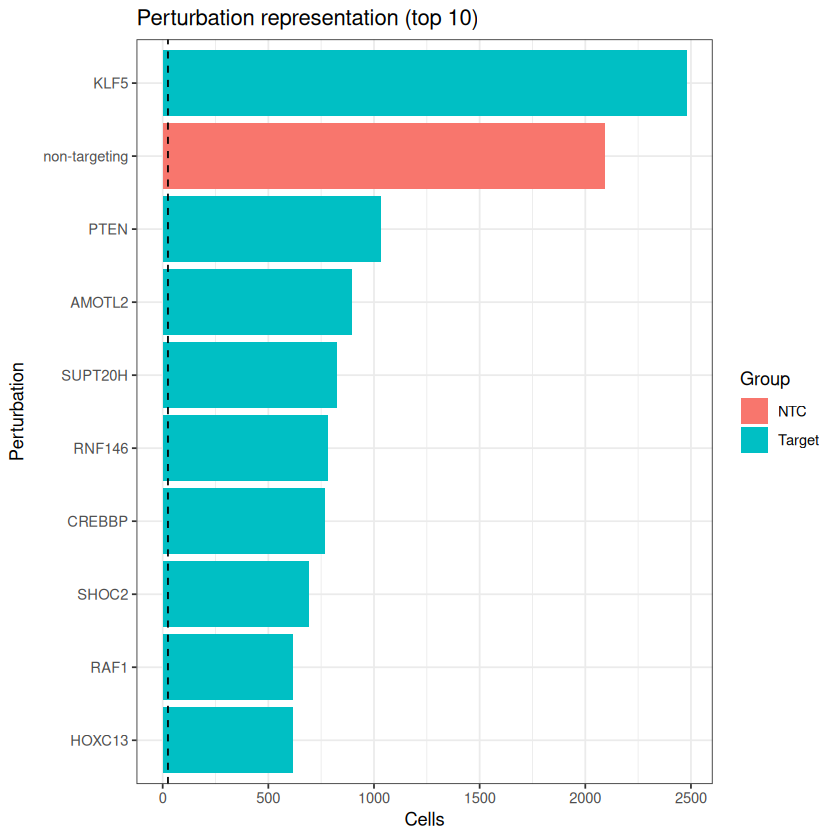

In [11]:
coverage_extra <- as.data.frame(table(perturbation=perturb_obj$perturb_label_extra), stringsAsFactors=FALSE) %>%
  rename(n_cells=Freq) %>% arrange(desc(n_cells)) %>%
  mutate(category=case_when(perturbation %in% control_labels_extra ~ "NTC",
                            perturbation %in% excluded_extra ~ "Excluded", TRUE ~ "Target"),
         eligible=n_cells >= min_cells_extra)
print(head(coverage_extra, 10))
cat("Targets with >=", min_cells_extra, "cells:", sum(coverage_extra$category=="Target" & coverage_extra$eligible), "\n")
plot_cov_extra <- coverage_extra %>% filter(category != "Excluded") %>% slice_head(n=10)
ggplot(plot_cov_extra, aes(x=reorder(perturbation,n_cells), y=n_cells, fill=category)) +
  geom_col() + coord_flip() + geom_hline(yintercept=min_cells_extra, linetype="dashed") +
  labs(title="Perturbation representation (top 10)", x="Perturbation", y="Cells", fill="Group") +
  theme_bw(base_size=11)

### QC diagnostics and sequencing depth by perturbation

Summarize detected genes, RNA UMIs, and mitochondrial fraction by perturbation and capture channel. These distributions can reveal technical artifacts before DEG calling. 

# A tibble: 15 × 5
   perturbation  n_cells median_nCount_RNA median_nFeature_RNA median_percent.mt
   <chr>           <int>             <dbl>               <dbl>             <dbl>
 1 KLF5             2479            15775                5163              0.154
 2 non-targeting    2093            13730                4751              0.144
 3 gene_desert      2063            13503                4691              0.145
 4 PTEN             1034            14268                4750              0.142
 5 AMOTL2            896            14160.               4767              0.139
 6 SUPT20H           824            13740.               4852              0.154
 7 RNF146            781            13549                4695              0.145
 8 CREBBP            770            14340.               4752.             0.141
 9 SHOC2             693            13569                4680              0.130
10 HOXC13            619            14399                4834              0.140
11 RAF1  

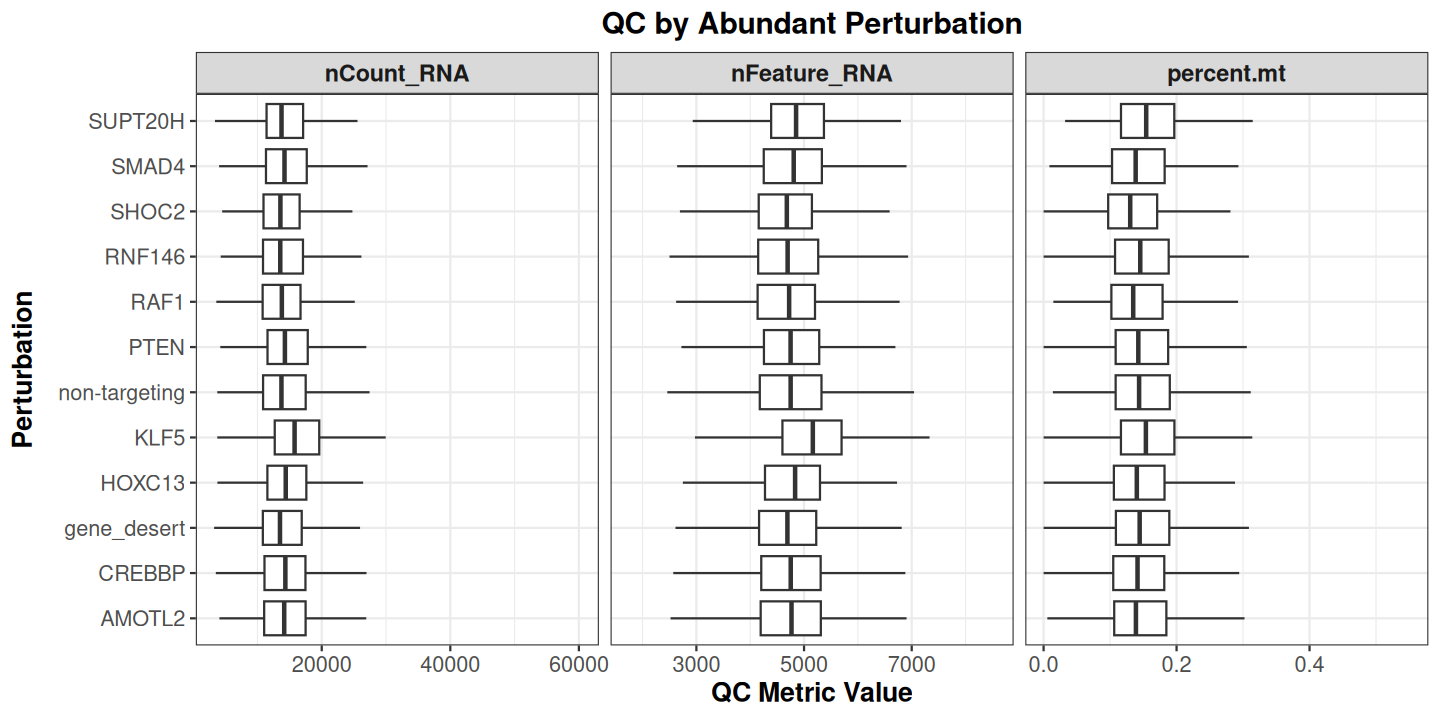

In [14]:
options(repr.plot.width = 12, repr.plot.height = 6)
qc_md_extra <- perturb_obj@meta.data %>%
  mutate(perturbation=perturb_obj$perturb_label_extra)
if (!"percent.mt" %in% names(qc_md_extra)) {
  mt_features_extra <- grep("^MT-", rownames(perturb_obj), value=TRUE)
  if(length(mt_features_extra)) {
    perturb_obj[["percent.mt"]] <- PercentageFeatureSet(perturb_obj, features=mt_features_extra)
    qc_md_extra$percent.mt <- perturb_obj$percent.mt
  }
}
qc_vars_extra <- intersect(c("nCount_RNA", "nFeature_RNA", "percent.mt"), names(qc_md_extra))
if (length(qc_vars_extra)) {
  qc_summary_extra <- qc_md_extra %>% group_by(perturbation) %>%
    summarise(n_cells=n(), across(all_of(qc_vars_extra), ~median(.x,na.rm=TRUE), .names="median_{.col}"), .groups="drop")
  print(head(qc_summary_extra %>% arrange(desc(n_cells)), 15))
  qc_long_extra <- qc_md_extra %>%
    filter(perturbation %in% head(coverage_extra$perturbation, 12)) %>%
    select(perturbation, all_of(qc_vars_extra)) %>%
    pivot_longer(all_of(qc_vars_extra), names_to="metric", values_to="value")
    
    print(ggplot(qc_long_extra, aes(x=value, y=perturbation)) +
      geom_boxplot(outlier.shape=NA) +
      facet_wrap(~metric, scales="free_x", nrow=1) +
      theme_bw(base_size=14) +
      labs(title="QC by Abundant Perturbation", x="QC Metric Value", y="Perturbation") +
      theme(plot.title=element_text(size=18,face="bold",hjust=0.5),
            axis.title=element_text(size=16,face="bold"),
            axis.text=element_text(size=13),
            strip.text=element_text(size=14,face="bold")))
        

} else message("RNA QC fields are absent; skip QC panel.")

### Channel balance and potential confounding

Visualize whether each perturbation is represented in both independent capture channels. Strong channel imbalance can look like a perturbation effect

# A tibble: 30 × 4
   perturbation channel     n fraction
   <chr>        <chr>   <int>    <dbl>
 1 AMOTL2       Ch1       423    0.472
 2 AMOTL2       Ch2       473    0.528
 3 BMPR1A       Ch1       240    0.472
 4 BMPR1A       Ch2       269    0.528
 5 CREBBP       Ch1       371    0.482
 6 CREBBP       Ch2       399    0.518
 7 HOXC13       Ch1       304    0.491
 8 HOXC13       Ch2       315    0.509
 9 IRF2         Ch1       235    0.461
10 IRF2         Ch2       275    0.539
# ℹ 20 more rows


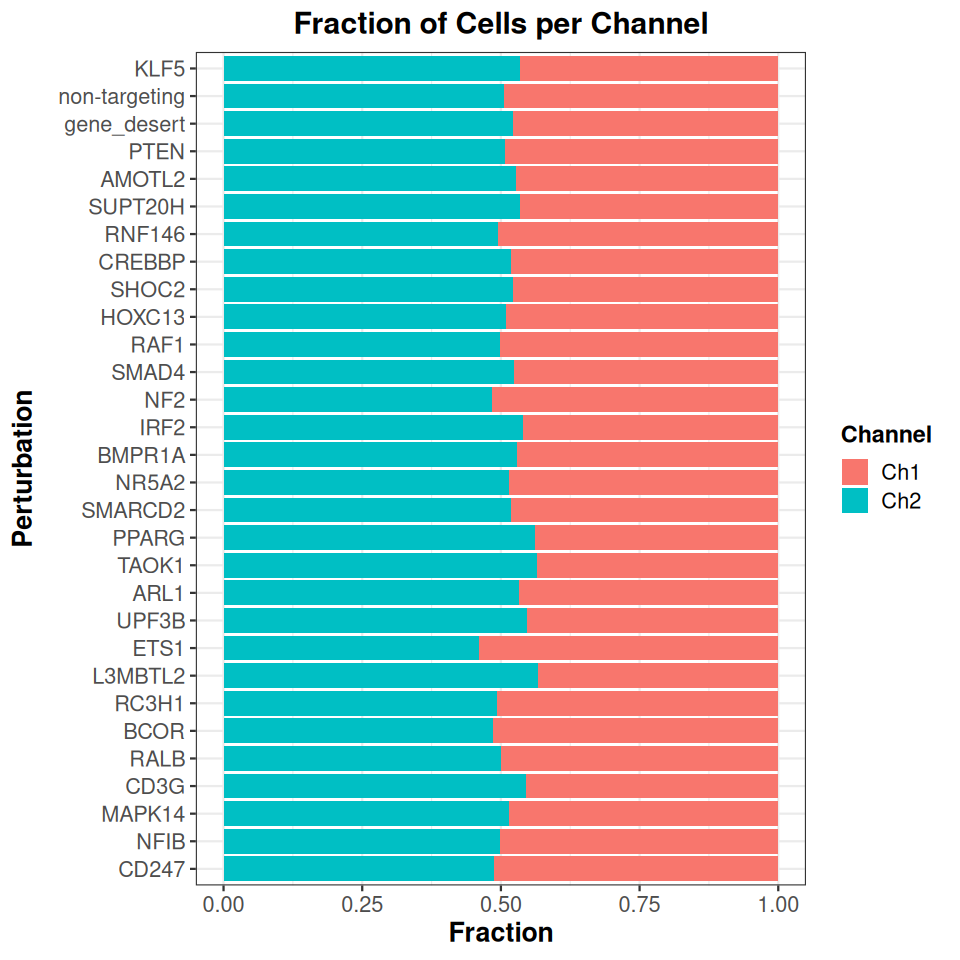

In [15]:
options(repr.plot.width = 8, repr.plot.height = 8)

if (!is.null(channel_col_extra)) {

  channel_tab_extra <- qc_md_extra %>%
    mutate(channel = as.character(.data[[channel_col_extra]])) %>%
    count(perturbation, channel, name = "n") %>%
    group_by(perturbation) %>%
    mutate(fraction = n / sum(n)) %>%
    ungroup()

  # Select top 30 perturbations
  top_perturbations <- head(coverage_extra$perturbation, 30)

  plot_data <- channel_tab_extra %>%
    filter(perturbation %in% top_perturbations) %>%
    mutate(
      perturbation = factor(
        perturbation,
        levels = rev(top_perturbations)
      )
    )

  # Plot channel fractions
  print(
    ggplot(
      plot_data,
      aes(x = perturbation, y = fraction, fill = channel)
    ) +
      geom_col() +
      coord_flip() +
      theme_bw(base_size = 14) +
      labs(
        title = "Fraction of Cells per Channel",
        x = "Perturbation",
        y = "Fraction",
        fill = "Channel"
      ) +
    theme(
      plot.title = element_text(size=18, face="bold", hjust=0.5),
      axis.title = element_text(size=16, face="bold"),
      axis.text = element_text(size=13),
      legend.title = element_text(size=14, face="bold"),
      legend.text = element_text(size=13)
    )
  )

  print(
    channel_tab_extra %>%
      filter(perturbation %in%
               head(coverage_extra$perturbation, 15))
  )

} else {
  message("No channel field detected.")
}

### Cell-state distribution and perturbation–cluster association

Compare the fraction of cells in each Seurat cluster across perturbations. Fisher tests are useful for **screening** unusual distributions, but cell-level p-values can be overly optimistic when cells share experimental batches or biological samples.

   perturbation      p_value     p_adj_BH
1          KLF5 0.0004997501 0.0009995002
2        AMOTL2 0.0004997501 0.0009995002
3       SUPT20H 0.0004997501 0.0009995002
4        RNF146 0.0004997501 0.0009995002
5        CREBBP 0.0004997501 0.0009995002
6           NF2 0.0004997501 0.0009995002
7         SHOC2 0.0014992504 0.0025701435
8          PTEN 0.0024987506 0.0037481259
9         SMAD4 0.0179910045 0.0239880060
10         IRF2 0.0209895052 0.0251874063
11       HOXC13 0.1219390305 0.1330243969
12         RAF1 0.1514242879 0.1514242879


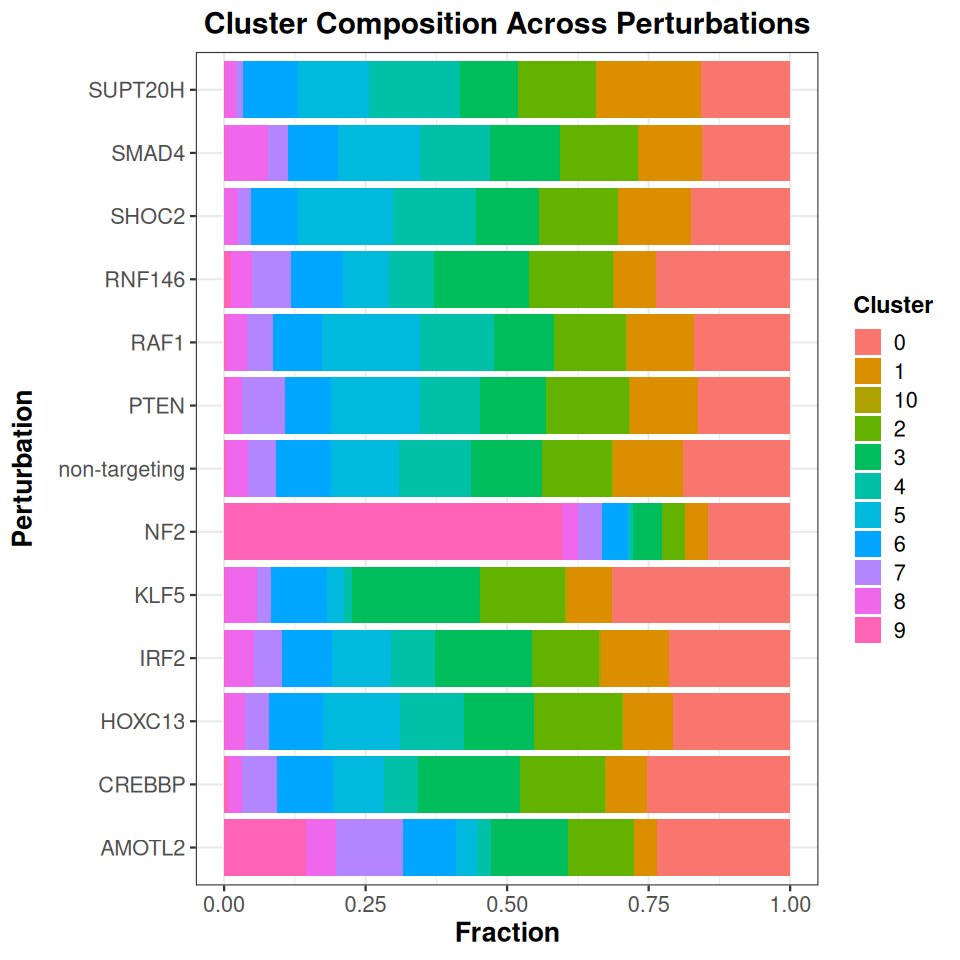

In [16]:
if (!"seurat_clusters" %in% names(perturb_obj@meta.data)) {
  message("No Seurat clusters found; skip cluster-composition analysis.")
} else {
  cluster_md_extra <- perturb_obj@meta.data %>%
    mutate(perturbation=perturb_obj$perturb_label_extra, cluster=as.character(seurat_clusters))
  eligible_extra <- coverage_extra %>%
    filter(category=="Target", n_cells >= min_cells_extra) %>% pull(perturbation)
  top_targets_extra <- head(eligible_extra, max_targets_extra)
  cluster_prop_extra <- cluster_md_extra %>%
    filter(perturbation %in% c(control_labels_extra, top_targets_extra)) %>%
    count(perturbation, cluster, name="n") %>% group_by(perturbation) %>%
    mutate(fraction=n/sum(n)) %>% ungroup()

    print(ggplot(cluster_prop_extra, aes(x=perturbation, y=fraction, fill=cluster)) +
      geom_col() + coord_flip() + theme_bw(base_size=14) +
      labs(title="Cluster Composition Across Perturbations", x="Perturbation", y="Fraction", fill="Cluster") +
      theme(plot.title=element_text(size=18, face="bold", hjust=0.5),
            axis.title=element_text(size=16, face="bold"),
            axis.text=element_text(size=13),
            legend.title=element_text(size=14, face="bold"),
            legend.text=element_text(size=13)))

    
  # Compare each target to pooled NTC as a contingency-table diagnostic.
  cluster_tests_extra <- lapply(top_targets_extra, function(tgt) {
    dat <- cluster_md_extra %>% filter(perturbation %in% c(tgt,control_labels_extra)) %>%
      mutate(group=ifelse(perturbation==tgt,"target","NTC"))
    tab <- table(dat$group,dat$cluster)
    if(nrow(tab)<2 || ncol(tab)<2) return(NULL)
    p <- tryCatch(fisher.test(tab, simulate.p.value=TRUE, B=2000)$p.value, error=function(e) NA_real_)
    data.frame(perturbation=tgt,p_value=p)
  })
  cluster_tests_extra <- bind_rows(cluster_tests_extra) %>%
    mutate(p_adj_BH=p.adjust(p_value,method="BH")) %>% arrange(p_adj_BH)
  print(cluster_tests_extra)
}

### Perturbation-versus-NTC differential expression (DE)

For the most represented perturbations, run Seurat Wilcoxon DE against pooled non-targeting controls and plot the magnitude and significance of transcriptional responses. Use sample-level pseudobulk with biological replicates for confirmatory inference.

# A tibble: 12 × 4
   perturbation n_sig  n_up n_down
   <chr>        <int> <int>  <int>
 1 NF2           3675  2491   1184
 2 KLF5          2852  2343    509
 3 AMOTL2        1667   872    795
 4 SUPT20H       1496  1157    339
 5 CREBBP        1327   467    860
 6 SHOC2          979   377    602
 7 PTEN           830   312    518
 8 SMAD4          688   335    353
 9 RAF1           478   207    271
10 RNF146         457   147    310
11 IRF2           414   190    224
12 HOXC13         290   119    171


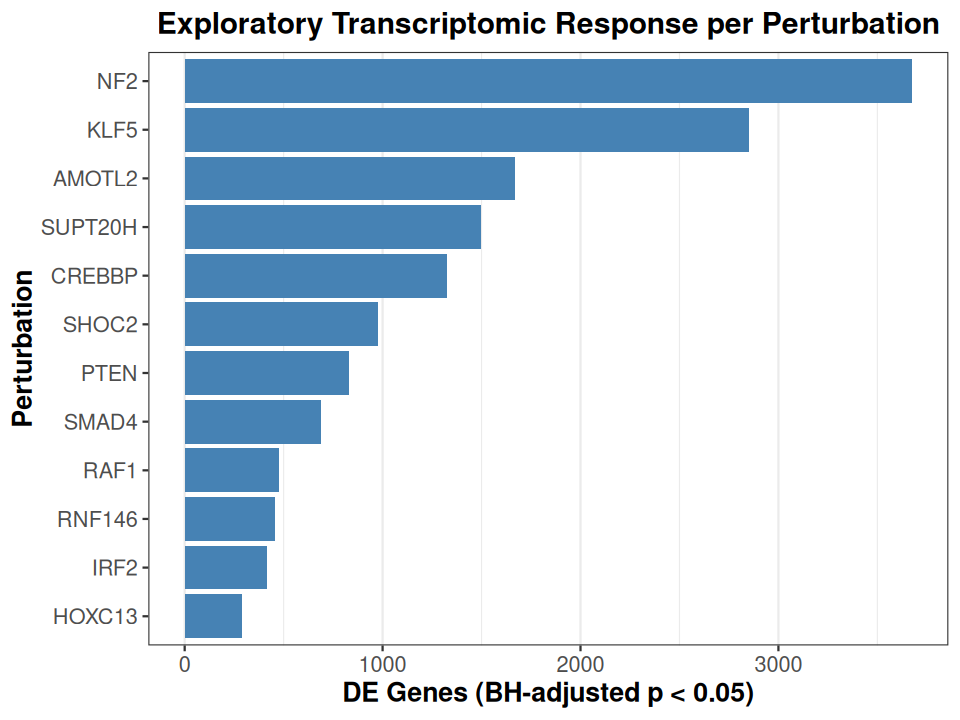

In [17]:
options(repr.plot.width=8, repr.plot.height=6)
DefaultAssay(perturb_obj) <- "SCT"
Idents(perturb_obj) <- "perturb_label_extra"
ntc_cells_extra <- WhichCells(perturb_obj, idents=control_labels_extra)

if(length(ntc_cells_extra) < min_cells_extra) stop("Insufficient NTC cells for DEG analysis.")

targets_for_de_extra <- coverage_extra %>%
  filter(category=="Target", eligible) %>%
  slice_head(n=max_targets_extra) %>% pull(perturbation)
# Multiple SCT models may require correction before DEG testing.
if (length(slot(perturb_obj[["SCT"]], "SCTModel.list")) > 1L) {
  perturb_obj <- PrepSCTFindMarkers(perturb_obj, verbose=FALSE)
}

# deg_results_extra <- lapply(targets_for_de_extra, function(tgt) {
#   # message("Comparing ", tgt, " to pooled NTC")
#   tgt_cells <- WhichCells(perturb_obj, idents=tgt)
#   tryCatch({
#     out <- FindMarkers(perturb_obj, ident.1=tgt_cells, ident.2=ntc_cells_extra,
#                        assay="SCT", test.use="wilcox", 
#                        min.pct=0.1,
#                        # logfc.threshold=0, 
#                        verbose=FALSE)
      
#     fc_col <- intersect(c("avg_log2FC","avg_logFC"), names(out))[1]
#     if(is.na(fc_col)) stop("Cannot locate a log-fold-change column")
#     out %>% rownames_to_column("gene") %>%
#       mutate(log2FC= .data[[fc_col]], perturbation=tgt,
#              p_adj_within_target=p_val_adj) %>%
#       select(perturbation,gene,log2FC,p_val,p_adj_within_target,everything())
#   }, error=function(e) {message("Skipping ",tgt,": ",conditionMessage(e)); NULL})
# })
deg_results_extra <- lapply(targets_for_de_extra, function(tgt) {
  tgt_cells <- WhichCells(perturb_obj, idents=tgt)
  tryCatch({
    out <- FindMarkers(perturb_obj, ident.1=tgt_cells, ident.2=ntc_cells_extra,
                       assay="SCT", test.use="wilcox", min.pct=0.1,
                       logfc.threshold=0.1, recorrect_umi=FALSE, verbose=FALSE)
    fc_col <- intersect(c("avg_log2FC","avg_logFC"), names(out))[1]
    if(is.na(fc_col)) stop("Cannot locate a log-fold-change column")
    out %>% rownames_to_column("gene") %>%
      mutate(log2FC=.data[[fc_col]], perturbation=tgt, p_adj_within_target=p_val_adj) %>%
      select(perturbation,gene,log2FC,p_val,p_adj_within_target,everything())
  }, error=function(e) {message("Skipping ",tgt,": ",conditionMessage(e)); NULL})
})

deg_results_extra <- bind_rows(deg_results_extra)

if(nrow(deg_results_extra)) {
  # The genes returned by FindMarkers may be filtered by min.pct.
  # BH here is across the *reported* tests, not an all-gene genome-wide guarantee.
  deg_results_extra <- deg_results_extra %>%
    mutate(p_adj_screen=p.adjust(p_val,method="BH"),
           significant=p_adj_screen<0.05 & abs(log2FC)>0.25)
  deg_summary_extra <- deg_results_extra %>% group_by(perturbation) %>%
    summarise(n_sig=sum(significant,na.rm=TRUE),
              n_up=sum(significant & log2FC>0,na.rm=TRUE),
              n_down=sum(significant & log2FC<0,na.rm=TRUE),
              .groups="drop") %>% arrange(desc(n_sig))
  print(deg_summary_extra)

  print(ggplot(deg_summary_extra, aes(reorder(perturbation,n_sig),n_sig)) +
      geom_col(fill="steelblue") + coord_flip() + theme_bw(base_size=14) +
      labs(title="Exploratory Transcriptomic Response per Perturbation",
           x="Perturbation", y="DE Genes (BH-adjusted p < 0.05)") +
      theme(plot.title=element_text(size=18,face="bold",hjust=0.5),
            axis.title=element_text(size=16,face="bold"),
            axis.text=element_text(size=13),
            panel.grid.major.y=element_blank()))
    
} else message("No DEG results. Check perturbation labels, SCT assay and control counts.")

### Volcano plot for a selected perturbation

Explore the highest-effect genes for one perturbation; The plot uses **screen-wide adjusted p-values** from the previous section.

      gene    log2FC  p_adj_screen
1   AKR1C2 -3.437462 8.156258e-198
2   AKR1C3 -3.136440 9.883745e-186
3     AGR2 -3.489848 7.013473e-185
4     CAV1  2.491621 2.330537e-182
5   SLC2A3  2.933720 1.627411e-173
6   ANTXR1  2.684597 1.944083e-173
7    MTUS1 -2.686156 2.221387e-168
8    UPK3B  3.647476 2.559225e-166
9     G6PD -1.123820 5.275276e-165
10 SLC12A2 -2.918641 8.847779e-164
11   PSMB9  2.835587 1.616944e-159
12   CPLX2 -3.156684 4.111126e-159
13  IGFBP3  3.841590 8.057912e-156
14 ALDH3A1 -2.380201 3.498271e-154
15    EML4 -1.477620 1.393946e-150
16    GPX2 -3.385060 1.225592e-149
17   AHNAK  2.149421 1.753177e-149
18   MGST1 -1.155304 1.930334e-146
19    CAV2  1.883193 1.636606e-140
20    MALL -2.611271 1.814571e-140


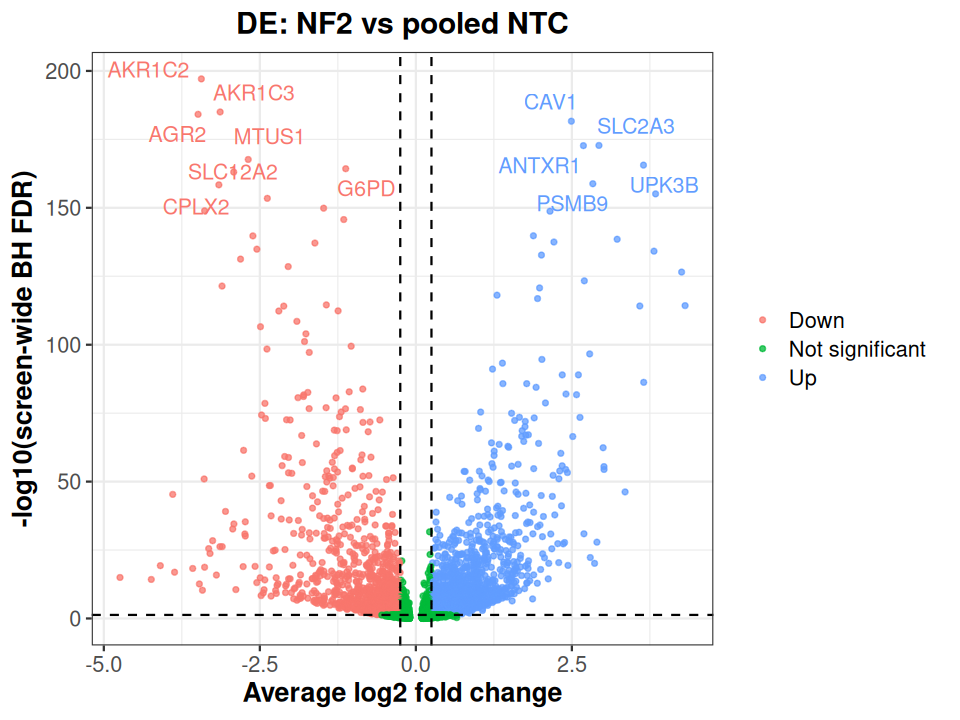

In [19]:
options(repr.plot.width=8, repr.plot.height=6)

if (exists("deg_results_extra") && nrow(deg_results_extra)) {
  library(ggrepel)
  selected_target_extra <- deg_summary_extra$perturbation[1]  # or set e.g. "HDAC1"
  volcano_extra <- deg_results_extra %>% filter(perturbation==selected_target_extra) %>%
    mutate(neglog10FDR=-log10(pmax(p_adj_screen,1e-300)),
           direction=case_when(significant & log2FC>0 ~ "Up",
                               significant & log2FC<0 ~ "Down",
                               TRUE ~ "Not significant"))
  label_df_extra <- volcano_extra %>% filter(significant) %>% arrange(p_adj_screen, desc(abs(log2FC))) %>% slice_head(n=12)
  print(ggplot(volcano_extra, aes(log2FC, neglog10FDR, color=direction)) +
    geom_point(size=1.2, alpha=0.75) +
    geom_vline(xintercept=c(-0.25,0.25), linetype="dashed") +
    geom_hline(yintercept=-log10(0.05), linetype="dashed") +
    geom_text_repel(data=label_df_extra, aes(label=gene), size=4.5, max.overlaps=Inf, box.padding=0.4, point.padding=0.2, show.legend=FALSE) +
    theme_bw(base_size=14) +
    labs(title=paste("DE:", selected_target_extra, "vs pooled NTC"),
         x="Average log2 fold change", y="-log10(screen-wide BH FDR)", color=NULL) +
    theme(plot.title=element_text(size=18, face="bold", hjust=0.5),
          axis.title=element_text(size=16, face="bold"),
          axis.text=element_text(size=13),
          legend.text=element_text(size=13)))
  print(volcano_extra %>% arrange(p_adj_screen) %>% select(gene, log2FC, p_adj_screen) %>% head(20))
}

### On-target suppression across multiple perturbations

Estimate targeted-gene expression changes relative to NTC for perturbation labels that match genes present in the RNA assay. This assesses intended target suppression but cannot independently verify guide identity or editing efficiency.

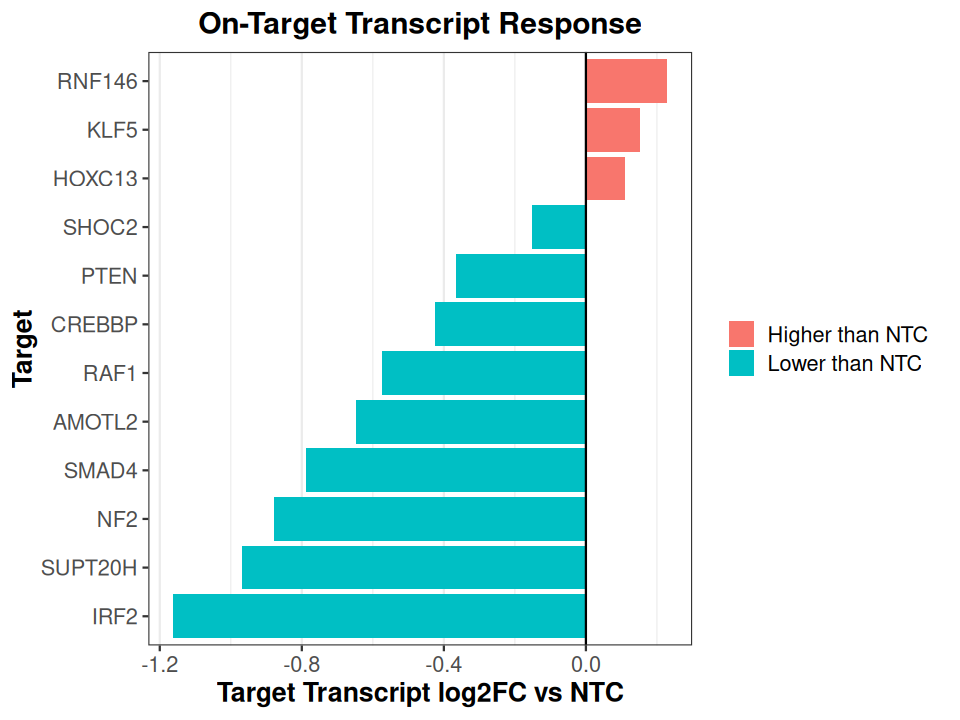

In [21]:
options(repr.plot.width=8, repr.plot.height=6)
print(ggplot(on_target_extra, aes(reorder(perturbation,log2FC),log2FC,fill=response)) +
  geom_col() + coord_flip() + geom_hline(yintercept=0) +
  theme_bw(base_size=14) +
  labs(title="On-Target Transcript Response", x="Target",
       y="Target Transcript log2FC vs NTC", fill=NULL) +
  theme(plot.title=element_text(size=18,face="bold",hjust=0.5),
        axis.title=element_text(size=16,face="bold"),
        axis.text=element_text(size=13),
        legend.title=element_text(size=14),
        legend.text=element_text(size=13),
        panel.grid.major.y=element_blank()))

### Shared DE signatures and perturbation similarity

Cluster perturbations by their **NTC-referenced log-fold-change signatures**, rather than raw mean expression. This reduces the influence of baseline cell-state signals, but does not remove channel confounding. Only genes with complete DE results across selected targets are included.

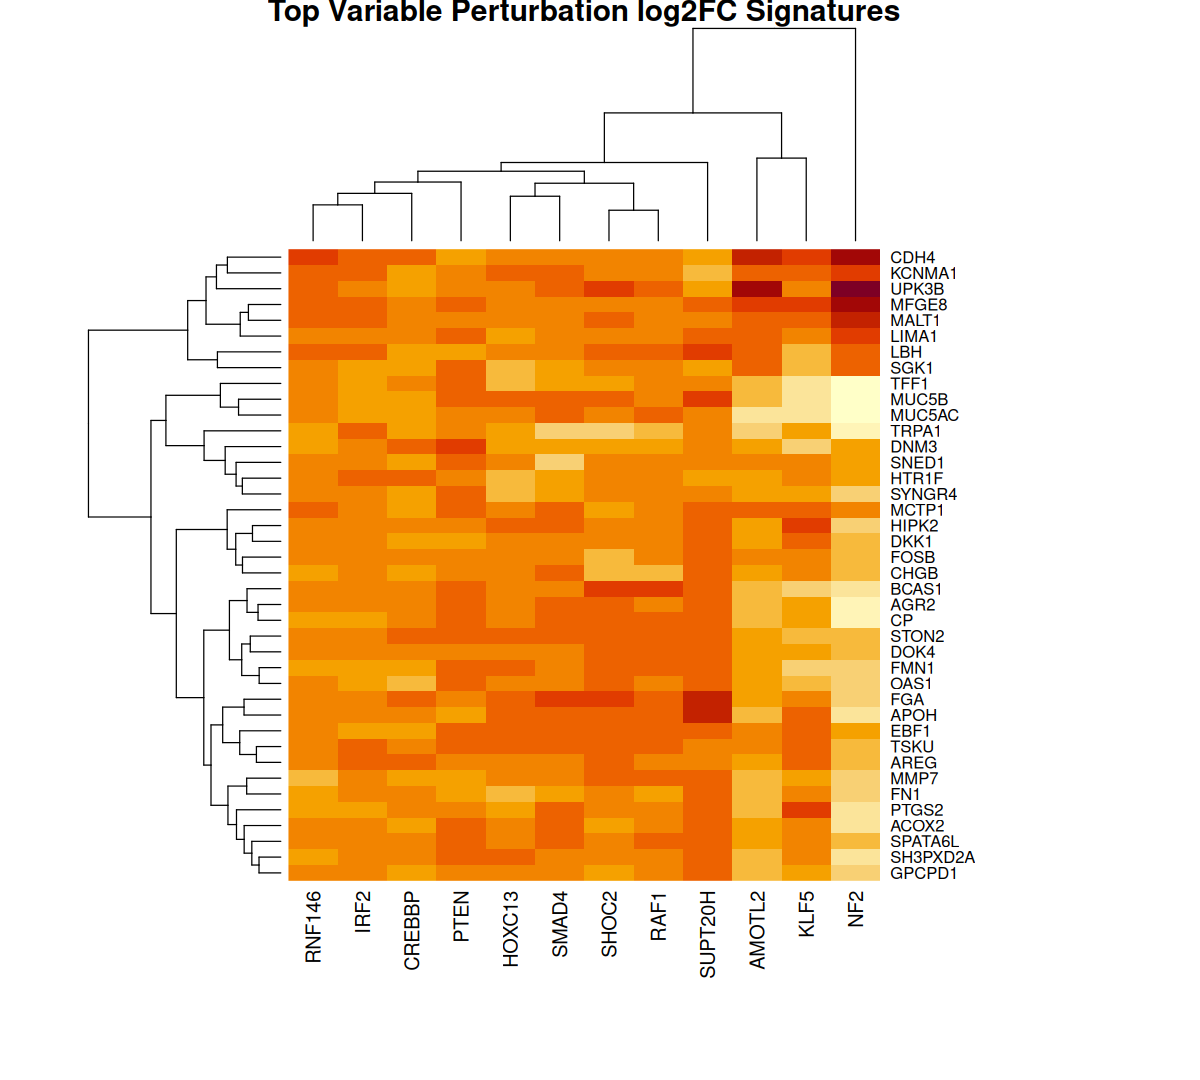

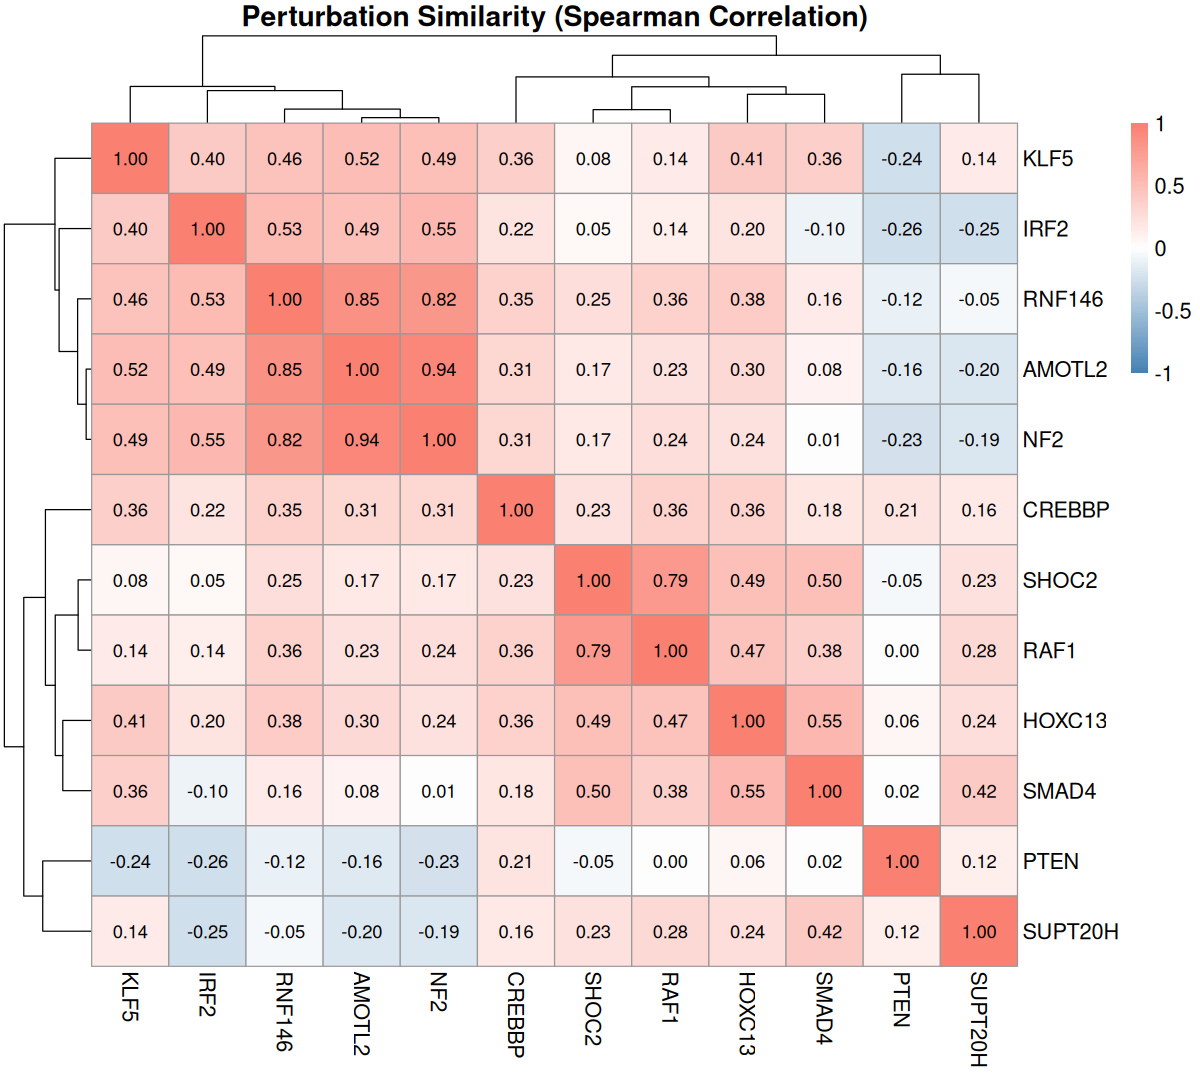

In [26]:
options(repr.plot.width=10, repr.plot.height=9)
if (exists("deg_results_extra") && nrow(deg_results_extra)) {
  selected_for_similarity_extra <- head(deg_summary_extra$perturbation,max_targets_extra)
  sig_wide_extra <- deg_results_extra %>%
    filter(perturbation %in% selected_for_similarity_extra) %>%
    select(gene,perturbation,log2FC) %>%
    distinct(gene,perturbation,.keep_all=TRUE) %>%
    pivot_wider(names_from=perturbation,values_from=log2FC)
  sig_wide_extra <- sig_wide_extra[complete.cases(sig_wide_extra),,drop=FALSE]
  if(nrow(sig_wide_extra)>=5 && ncol(sig_wide_extra)>=3) {
    sig_mat_extra <- as.matrix(sig_wide_extra[,-1,drop=FALSE]); rownames(sig_mat_extra) <- sig_wide_extra$gene
    # Restrict to variable perturbation-response genes for interpretable heatmap.
    gene_variance_extra <- apply(sig_mat_extra,1,var)
    top_sig_genes_extra <- names(sort(gene_variance_extra,decreasing=TRUE))[seq_len(min(40,length(gene_variance_extra)))]
    cor_sig_extra <- cor(sig_mat_extra, method="spearman", use="pairwise.complete.obs")
    
    heatmap(sig_mat_extra[top_sig_genes_extra,,drop=FALSE], scale="none",
            main="Top Variable Perturbation log2FC Signatures",
            cexRow=1.0, cexCol=1.2, cex.main=1.5, margins=c(10,12))
    
    pheatmap::pheatmap(cor_sig_extra,
      color=colorRampPalette(c("steelblue","white","salmon"))(100),
      breaks=seq(-1,1,length.out=101),
      cluster_rows=TRUE, cluster_cols=TRUE,
      display_numbers=TRUE, number_format="%.2f",
      number_color="black",
      fontsize=13, fontsize_row=13, fontsize_col=13,
      fontsize_number=11,
      main="Perturbation Similarity (Spearman Correlation)")
      
      
  } else message("Insufficient overlapping genes/targets for signature clustering.")
}

### Perturbation Similarity Analysis

Spearman correlation analysis revealed distinct patterns of transcriptional responses across CRISPR perturbations. **NF2, AMOTL2, and RNF146** showed strong positive correlations (ρ = 0.82–0.94), suggesting shared downstream regulatory effects. Similarly, **SHOC2 and RAF1** exhibited a strong correlation (ρ = 0.79), consistent with their involvement in RAS–MAPK signaling. In contrast, **PTEN** displayed weak or negative correlations with most other perturbations, indicating a relatively distinct transcriptional response. Overall, these findings highlight potential functional relationships among perturbations and demonstrate the utility of Perturb-seq for identifying shared transcriptional signatures.

### GO biological processes altered by a selected perturbation

Unlike the earlier target-library enrichment, this tests the **response genes** identified after perturbing a target. It uses all genes tested for that perturbation as the enrichment universe to reduce background bias. Requires `clusterProfiler` and `org.Hs.eg.db`.





'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“0.79% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in bitr(gene, fromType = fromType, toType = "ENTREZID", OrgDb = OrgDb):
“0.98% of input gene IDs are fail to map...”


                                                        Description
GO:0007155                                            cell adhesion
GO:0048646 anatomical structure formation involved in morphogenesis
GO:0072359                           circulatory system development
GO:0040011                                               locomotion
GO:0001944                                  vasculature development
GO:0040012                                 regulation of locomotion
GO:0035295                                         tube development
GO:2000145                              regulation of cell motility
GO:0001568                                 blood vessel development
GO:0030334                             regulation of cell migration
GO:0022603         regulation of anatomical structure morphogenesis
GO:0030029                             actin filament-based process
GO:0035239                                       tube morphogenesis
GO:0048514                               blood v

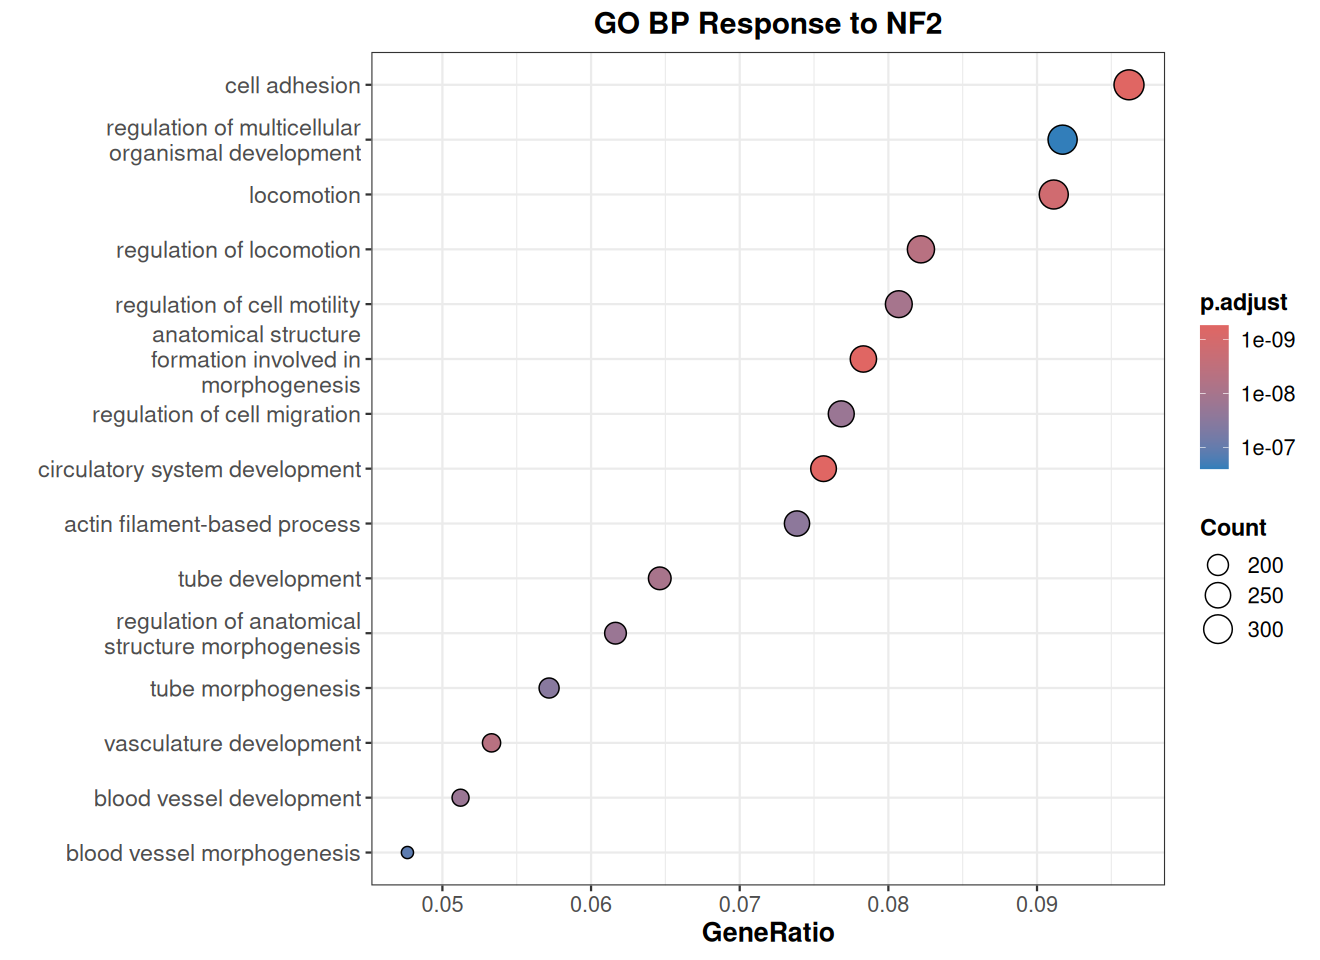

In [27]:
options(repr.plot.width=11, repr.plot.height=8)

if (exists("deg_results_extra") && nrow(deg_results_extra) &&
    requireNamespace("clusterProfiler",quietly=TRUE) && requireNamespace("org.Hs.eg.db",quietly=TRUE) &&
    requireNamespace("enrichplot",quietly=TRUE)) {
  go_target_extra <- deg_summary_extra$perturbation[1]
  go_dat_extra <- deg_results_extra %>% filter(perturbation==go_target_extra)
  response_symbols_extra <- unique(go_dat_extra$gene[go_dat_extra$significant])
  tested_symbols_extra <- unique(go_dat_extra$gene)
  if(length(response_symbols_extra)>=10) {
    go_response_extra <- tryCatch(clusterProfiler::enrichGO(
      gene=response_symbols_extra, universe=tested_symbols_extra,
      OrgDb=org.Hs.eg.db::org.Hs.eg.db, keyType="SYMBOL",ont="BP",
      pAdjustMethod="BH",pvalueCutoff=0.05,qvalueCutoff=0.2,readable=TRUE),
      error=function(e) {message(conditionMessage(e));NULL})
    if(!is.null(go_response_extra) && nrow(as.data.frame(go_response_extra))) {
        
    print(enrichplot::dotplot(go_response_extra, showCategory=15) +
      ggtitle(paste("GO BP Response to",go_target_extra)) +
      theme_bw(base_size=14) +
      theme(plot.title=element_text(size=18,face="bold",hjust=0.5),
            axis.title=element_text(size=16,face="bold"),
            axis.text=element_text(size=13),
            axis.text.y=element_text(size=14),
            legend.title=element_text(size=14,face="bold"),
            legend.text=element_text(size=13)))
        
      print(head(as.data.frame(go_response_extra)[,c("Description","p.adjust","Count")],15))
    } else message("No significant enriched GO terms for ",go_target_extra)
  } else message("Fewer than 10 significant response genes; skip GO for ",go_target_extra)
}

### GO Biological Process Enrichment Following NF2 Perturbation

GO enrichment analysis of differentially expressed genes following **NF2 perturbation** revealed significant enrichment of biological processes related to **cell adhesion, cell migration, motility, and cytoskeletal organization**. Cell adhesion showed the highest gene ratio (~0.096), while processes involving locomotion, actin filament organization, and tissue morphogenesis were also strongly enriched. These findings suggest that NF2 perturbation affects transcriptional programs associated with cell structure, movement, and adhesion, consistent with its established role in regulating cytoskeletal dynamics and Hippo signaling.

### Within-channel consistency checks

For an individual target with enough cells in **each** channel, compute independent channel-stratified log-fold changes. Concordance in direction across channels is useful, although technical channels still do not substitute for biological replicates.

Channel agreement, Spearman rho: 0.7778742 


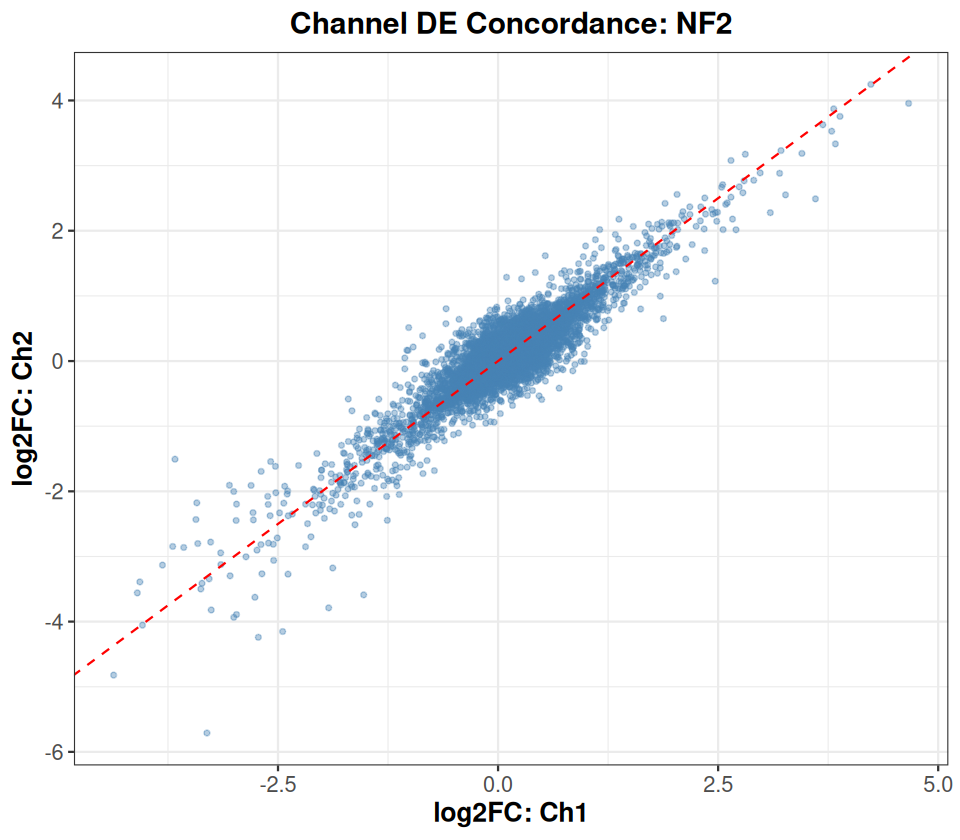

In [28]:
options(repr.plot.width=8, repr.plot.height=7)

if (!is.null(channel_col_extra) && exists("deg_summary_extra") && nrow(deg_summary_extra)) {
  consistency_target_extra <- deg_summary_extra$perturbation[1]
  channel_values_extra <- unique(as.character(perturb_obj@meta.data[[channel_col_extra]]))
  channel_de_extra <- lapply(channel_values_extra,function(ch) {
    cells_ch <- rownames(perturb_obj@meta.data)[as.character(perturb_obj@meta.data[[channel_col_extra]])==ch]
    tgt_ch <- intersect(cells_ch,WhichCells(perturb_obj,idents=consistency_target_extra))
    ntc_ch <- intersect(cells_ch,ntc_cells_extra)
    if(min(length(tgt_ch),length(ntc_ch))<min_cells_extra) {
      message("Skipping ",ch,": <",min_cells_extra," target or NTC cells")
      return(NULL)
    }
    tryCatch({
      tmp <- FindMarkers(perturb_obj,ident.1=tgt_ch,ident.2=ntc_ch,
                         assay="SCT",test.use="wilcox",min.pct=0.1,
                         logfc.threshold=0,verbose=FALSE)
      fc_col <- intersect(c("avg_log2FC","avg_logFC"),names(tmp))[1]
      tmp %>% rownames_to_column("gene") %>%
        transmute(gene,channel=ch,log2FC=.data[[fc_col]])
    },error=function(e) {message(conditionMessage(e));NULL})
  })
  channel_de_extra <- bind_rows(channel_de_extra)
  if(nrow(channel_de_extra) && n_distinct(channel_de_extra$channel)>=2) {
    ch_pair_extra <- channel_de_extra %>%
      group_by(gene) %>% filter(n()==2) %>% ungroup() %>%
      pivot_wider(names_from=channel,values_from=log2FC)
    if(ncol(ch_pair_extra)==3 && nrow(ch_pair_extra)>2) {
      x_extra <- ch_pair_extra[[2]]; y_extra <- ch_pair_extra[[3]]
      cat("Channel agreement, Spearman rho:",cor(x_extra,y_extra,method="spearman"),"\n")

      print(ggplot(ch_pair_extra, aes(x=.data[[names(ch_pair_extra)[2]]], y=.data[[names(ch_pair_extra)[3]]])) +
          geom_point(alpha=0.4, size=1.2, color="steelblue") +
          geom_abline(slope=1, intercept=0, linetype="dashed", color="red") +
          theme_bw(base_size=14) +
          labs(title=paste("Channel DE Concordance:", consistency_target_extra),
               x=paste("log2FC:", names(ch_pair_extra)[2]),
               y=paste("log2FC:", names(ch_pair_extra)[3])) +
          theme(plot.title=element_text(size=18, face="bold", hjust=0.5),
                axis.title=element_text(size=16, face="bold"),
                axis.text=element_text(size=13)))
        
    }
  } else message("Need at least two adequately represented channels for concordance.")
}

### Channel Concordance of NF2 Perturbation

Differential expression analysis of **NF2 perturbation** showed strong agreement between Channel 1 and Channel 2 (**Spearman ρ = 0.778**). Most genes exhibited consistent log2 fold changes across both channels, with a clear positive relationship and relatively few outliers. These results suggest that NF2-associated transcriptional responses are reproducible across the two capture channels, supporting the technical consistency of the Perturb-seq analysis.

## 6. Export results and reproducibility notes


In [30]:
# results_dir_extra <- results_dir
# if (!dir.exists(results_dir_extra)) dir.create(results_dir_extra,recursive=TRUE,showWarnings=FALSE)
# write.csv(coverage_extra,file.path(results_dir_extra,"perturbation_coverage.csv"),row.names=FALSE)
# if(exists("qc_summary_extra")) write.csv(qc_summary_extra,file.path(results_dir_extra,"perturbation_qc_summary.csv"),row.names=FALSE)
# if(exists("channel_tab_extra")) write.csv(channel_tab_extra,file.path(results_dir_extra,"perturbation_channel_balance.csv"),row.names=FALSE)
# if(exists("cluster_prop_extra")) write.csv(cluster_prop_extra,file.path(results_dir_extra,"perturbation_cluster_fractions.csv"),row.names=FALSE)
# if(exists("cluster_tests_extra")) write.csv(cluster_tests_extra,file.path(results_dir_extra,"cluster_association_screen.csv"),row.names=FALSE)
# if(exists("deg_results_extra") && nrow(deg_results_extra)) {
#   write.csv(deg_results_extra,file.path(results_dir_extra,"perturbation_vs_NTC_DE.csv"),row.names=FALSE)
#   write.csv(deg_summary_extra,file.path(results_dir_extra,"perturbation_DE_summary.csv"),row.names=FALSE)
# }
# if(exists("on_target_extra")) write.csv(on_target_extra,file.path(results_dir_extra,"on_target_transcript_response.csv"),row.names=FALSE)
# if(exists("channel_de_extra") && nrow(channel_de_extra)) write.csv(channel_de_extra,file.path(results_dir_extra,"within_channel_DE.csv"),row.names=FALSE)
# cat("Results written to:",results_dir_extra,"\n")
# cat("Interpretation: these are exploratory, cell-level results.\n")
# cat("For rigorous inference, collect biological replicates and use replicate-aware pseudobulk DE (e.g., edgeR or DESeq2).\n")
# print(sessionInfo())